# Particle Filtering for Robot Localization

A Python simulation exploring how two moving robots can be localized from noisy distance measurements. Each robot is represented by 1,000 particles over 10 movement steps.

Pacman measures distances to four fixed landmarks. The ghost measures only its distance to Pacman, so its update uses Pacman's resampled particle distribution rather than Pacman's true coordinates.

**My contributions:** particle weighting, normalization, cumulative-probability resampling, the ghost's sampled-Pacman update, diagnostic checks, and analysis of 10 experimental runs.

**Attribution:** The robot classes, movement and sensor models, visualization, evaluation function, initialization, and simulation scaffold were provided as course starter code. The implementation inside the marked student section and the experimental analysis were developed for the project. The original code comments are retained. Public sharing of starter-derived code is subject to course/instructor permission.

The assignment prompt, grading rubric, and instructor reference illustrations are not included in this portfolio copy. The original submission notebook is separate and unchanged.


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# world configuration
landmarks  = [[20.0, 20.0], [80.0, 80.0], [20.0, 80.0], [80.0, 20.0]]
world_size = 100.0

# generic robot implementation
class robot:
    def __init__(self):
        # initialise robot with random location and orientation
        self.x = random.random() * world_size
        self.y = random.random() * world_size
        self.orientation = random.random() * 2.0 * math.pi
        
        self.forward_noise = 0.0
        self.turn_noise    = 0.0
        self.sense_noise   = 0.0
    
    def set(self, new_x, new_y, new_orientation):
        if new_x < 0 or new_x >= world_size:
            raise ValueError('X coordinate out of bound')
        if new_y < 0 or new_y >= world_size:
            raise ValueError('Y coordinate out of bound')
        if new_orientation < 0 or new_orientation >= 2 * math.pi:
            raise ValueError('Orientation must be in [0..2pi]')
        self.x = float(new_x)
        self.y = float(new_y)
        self.orientation = float(new_orientation)

    def set_noise(self, new_f_noise, new_t_noise, new_s_noise):
        self.forward_noise = float(new_f_noise);
        self.turn_noise    = float(new_t_noise);
        self.sense_noise   = float(new_s_noise);
    
    # apply noisy movement to robot
    def new_position(self, turn, forward):
        if forward < 0:
            raise ValueError('Robot cant move backwards')
        
        # turn, and add randomness to the turning command
        orientation = self.orientation + float(turn) + random.gauss(0.0, self.turn_noise)
        orientation %= 2 * math.pi
        
        # move, and add randomness to the motion command
        dist = float(forward) + random.gauss(0.0, self.forward_noise)
        x = self.x + (math.cos(orientation) * dist)
        y = self.y + (math.sin(orientation) * dist)
        x %= world_size    # cyclic truncate
        y %= world_size

        return x, y, orientation
    
    # model noise using Gaussians
    def Gaussian(self, mu, sigma, x):
        # calculates the probability of x for 1-dim Gaussian with mean mu and var. sigma
        return math.exp(- ((mu - x) ** 2) / (sigma ** 2) / 2.0) / math.sqrt(2.0 * math.pi * (sigma ** 2))
    
# PacMan class
class pacman(robot):
    # the PacMan can sense its location using the landmarks
    def sense(self):
        Z = []
        for i in range(len(landmarks)):
            dist = math.sqrt((self.x - landmarks[i][0]) ** 2 + (self.y - landmarks[i][1]) ** 2)
            dist += random.gauss(0.0, self.sense_noise)
            Z.append(dist)
        return Z

    # calculates how likely a measurement should be
    def measurement_prob(self, measurement):
        prob = 1.0
        for i in range(len(landmarks)):
            dist = math.sqrt((self.x - landmarks[i][0]) ** 2 + (self.y - landmarks[i][1]) ** 2)
            prob *= self.Gaussian(dist, self.sense_noise, measurement[i])
        return prob

    def move(self, turn, forward):
        x, y, orientation = self.new_position(turn, forward)
        res = pacman()
        res.set(x, y, orientation)
        res.set_noise(self.forward_noise, self.turn_noise, self.sense_noise)
        return res

# Ghost class
class ghost(robot):
    # the PacMan ("mypacman") can sense its distance to the ghost
    def sense(self, mypacman):
        Z = math.sqrt((self.x - mypacman.x) ** 2 + (self.y - mypacman.y) ** 2) + random.gauss(0.0, self.sense_noise)
        return Z

    # calculates how likely a measurement should be
    def measurement_prob(self, measurement, mypacman):
        dist = math.sqrt((self.x - mypacman.x) ** 2 + (self.y - mypacman.y) ** 2)
        prob = self.Gaussian(dist, self.sense_noise, measurement)
        return prob

    def move(self, turn, forward):
        x, y, orientation = self.new_position(turn, forward)
        res = ghost()
        res.set(x, y, orientation)
        res.set_noise(self.forward_noise, self.turn_noise, self.sense_noise)
        return res

In [3]:
# world visualization with the distribution of particles
def show_belief(mypacman, pacman_particles, myghost, ghost_particles):
    plt.rcParams["figure.figsize"] = (5,5)

    for p in pacman_particles:
        plt.plot(p.x, p.y, marker=(3, 0, 180.0*p.orientation/math.pi), markerfacecolor='red', markersize=10, markeredgewidth=0.0, alpha=.3, linestyle='None')

    plt.plot(mypacman.x, mypacman.y, marker=(3, 0, 180.0*mypacman.orientation/math.pi), markerfacecolor='black', markersize=20, markeredgewidth=0.0, linestyle='None')

    for p in ghost_particles:
        plt.plot(p.x, p.y, marker=(5, 0, 180.0*p.orientation/math.pi), markerfacecolor='green', markersize=10, markeredgewidth=0.0, alpha=.3, linestyle='None')

    plt.plot(myghost.x, myghost.y, marker=(5, 0, 180.0*myghost.orientation/math.pi), markerfacecolor='black', markersize=20, markeredgewidth=0.0, linestyle='None')

    for x, y in landmarks:
          plt.plot(x, y, marker='o', markersize=20, markeredgewidth=2.0, markerfacecolor='None', markeredgecolor='blue')

    plt.xlim([0,100])
    plt.ylim([0,100])

    plt.show()

# measure the proximity between the real location and the distribution of particles
def eval(r, p):
    s = 0.0;
    for i in range(len(p)):
        dx = (p[i].x - r.x + (world_size/2.0)) % world_size - (world_size/2.0)
        dy = (p[i].y - r.y + (world_size/2.0)) % world_size - (world_size/2.0)
        err = math.sqrt(dx * dx + dy * dy)
        s += err
    return s / float(len(p))

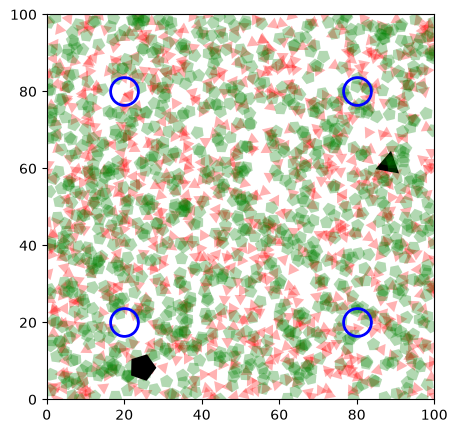

Average pacman distance: 38.23133522068303
Average ghost distance: 37.60960701338264


In [4]:
# pacman/ghost initialization
forward_noise = 3.0 
turn_noise = 0.05
sense_noise = 3.0

mypacman = pacman()
mypacman.set_noise(forward_noise, turn_noise, sense_noise)

myghost = ghost()
myghost.set_noise(forward_noise, turn_noise, sense_noise)

# particle distribution
N = 1000 # number of particles
T = 10   # number of moves

# initialise randomly guessed particles for pacman and ghost
p = []
g = []
for i in range(N):
    x = pacman()
    x.set_noise(forward_noise, turn_noise, sense_noise)
    p.append(x)
    x = ghost()
    x.set_noise(forward_noise, turn_noise, sense_noise)
    g.append(x)

show_belief(mypacman, p, myghost, g)

print("Average pacman distance:", eval(mypacman, p))
print("Average ghost distance:", eval(myghost, g))


Turn #1


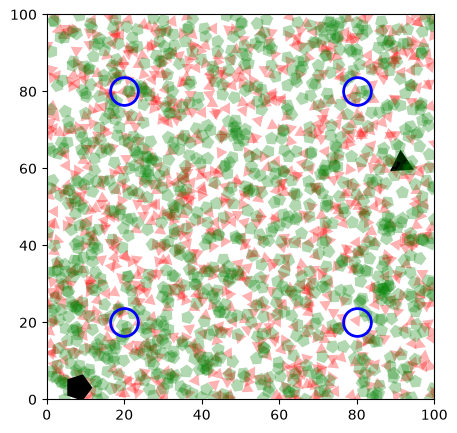

Average pacman distance before resample: 38.430938556168364
Average ghost distance before resample: 37.411506708123085


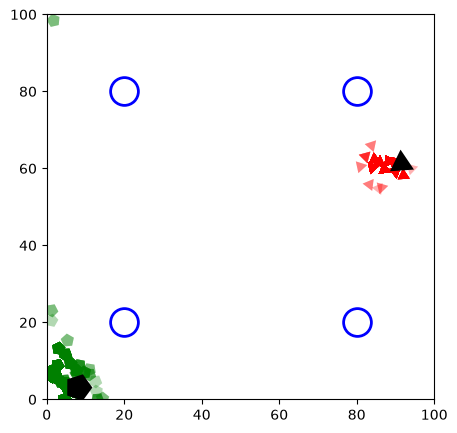

Average pacman distance after resample: 3.9553905446895143
Average ghost distance after resample: 5.646818018837479

Turn #2


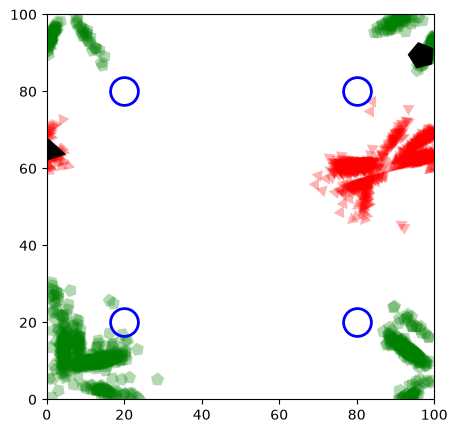

Average pacman distance before resample: 13.080523122345301
Average ghost distance before resample: 20.295055773373917


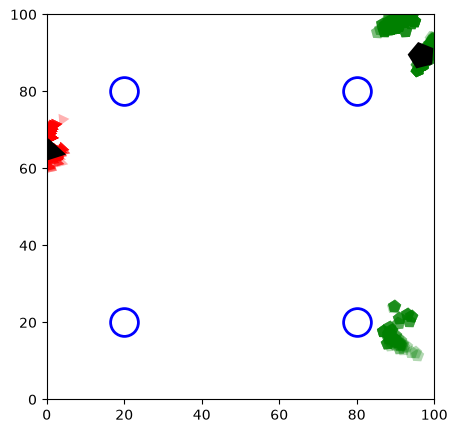

Average pacman distance after resample: 2.4282523150612834
Average ghost distance after resample: 10.866515485109478

Turn #3


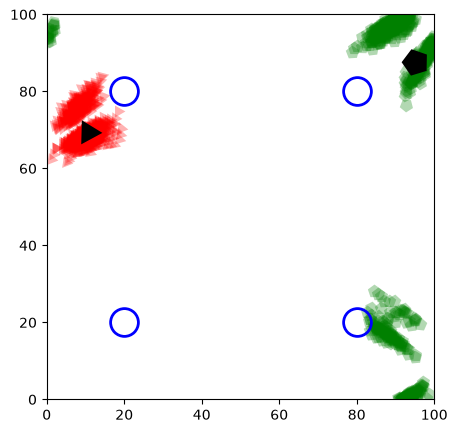

Average pacman distance before resample: 4.561314438497383
Average ghost distance before resample: 12.445433493606929


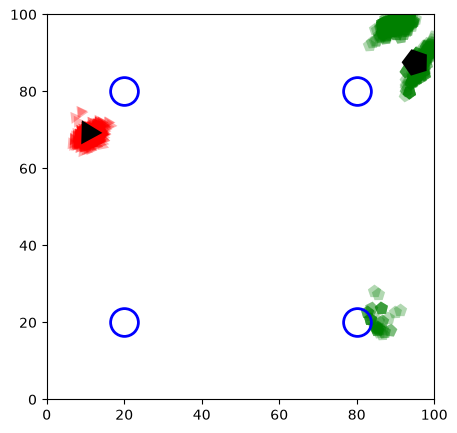

Average pacman distance after resample: 1.9847946613077525
Average ghost distance after resample: 9.996377036221688

Turn #4


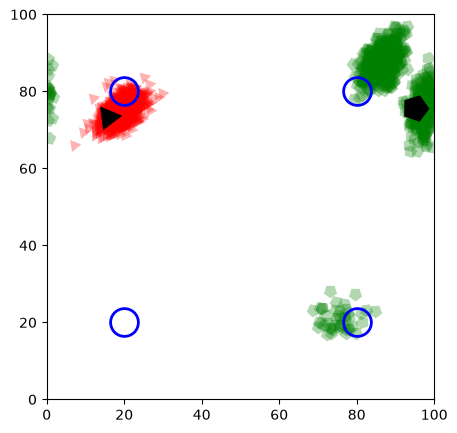

Average pacman distance before resample: 4.470827021149207
Average ghost distance before resample: 13.27390267610353


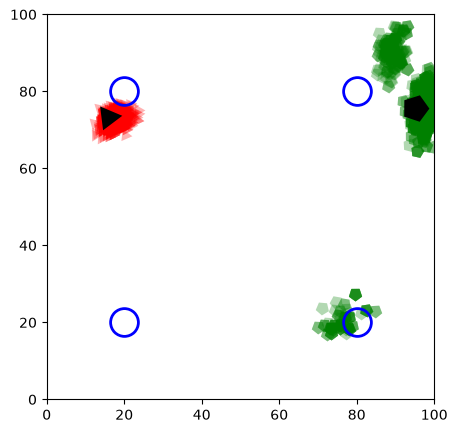

Average pacman distance after resample: 2.554132990246988
Average ghost distance after resample: 10.928108165548878

Turn #5


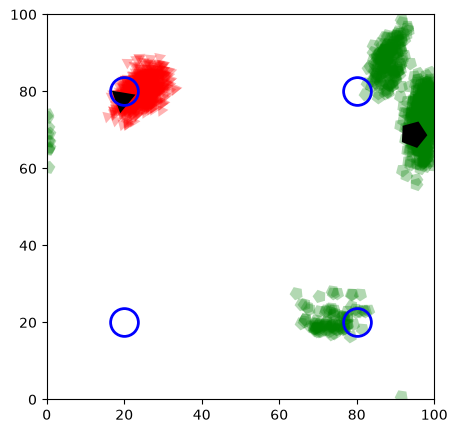

Average pacman distance before resample: 5.92871825195284
Average ghost distance before resample: 13.601299443925326


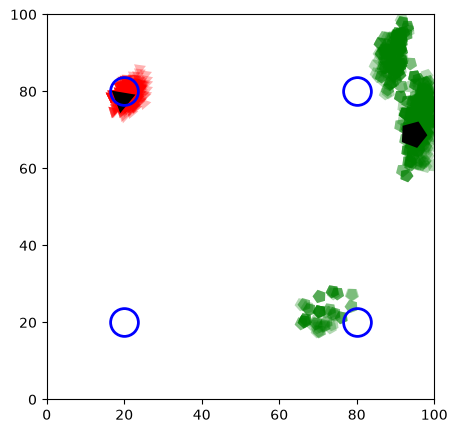

Average pacman distance after resample: 2.654397497133234
Average ghost distance after resample: 13.007186525688565

Turn #6


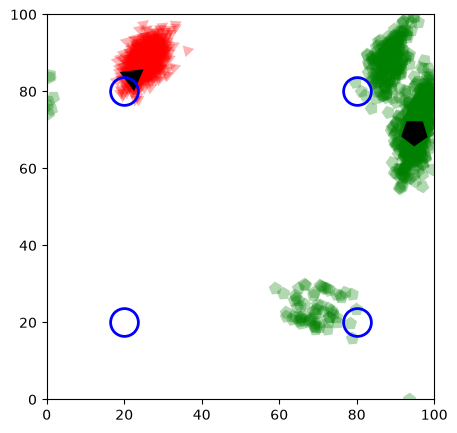

Average pacman distance before resample: 6.191707866539244
Average ghost distance before resample: 12.439839044908576


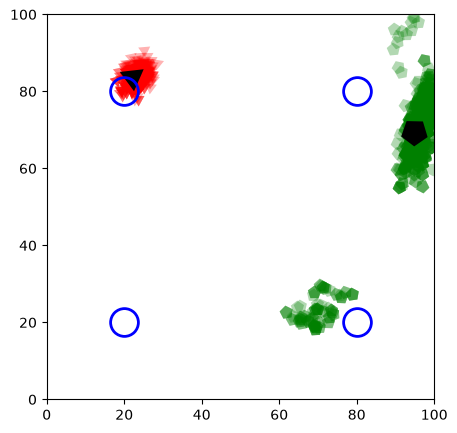

Average pacman distance after resample: 2.3607517396611843
Average ghost distance after resample: 10.51450843805312

Turn #7


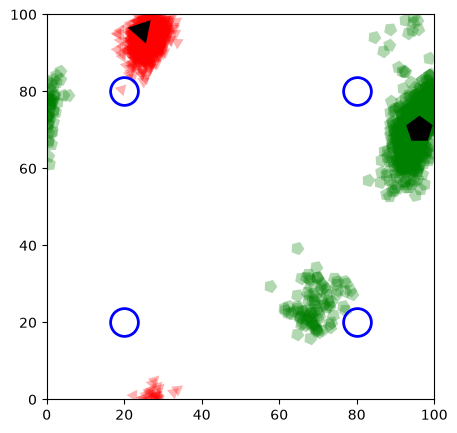

Average pacman distance before resample: 4.551664481590829
Average ghost distance before resample: 10.826202096311171


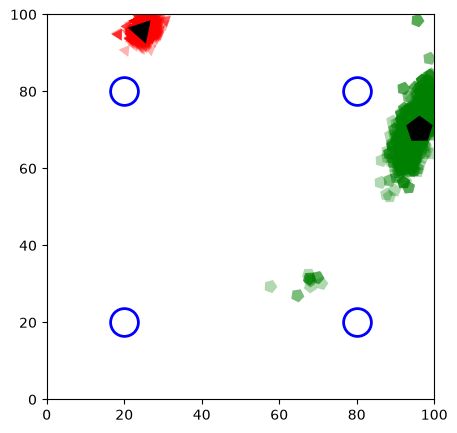

Average pacman distance after resample: 2.312791535439143
Average ghost distance after resample: 6.404583464068021

Turn #8


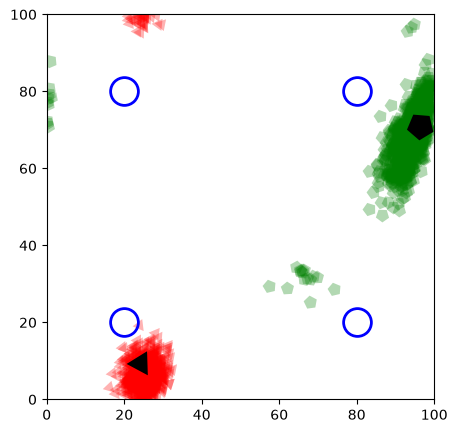

Average pacman distance before resample: 4.814582732205042
Average ghost distance before resample: 7.428340584521725


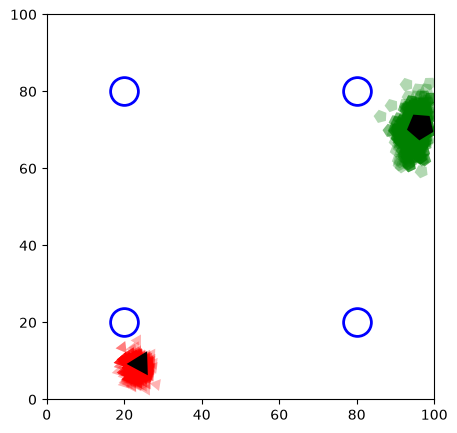

Average pacman distance after resample: 2.4442518246762917
Average ghost distance after resample: 3.9716073040742903

Turn #9


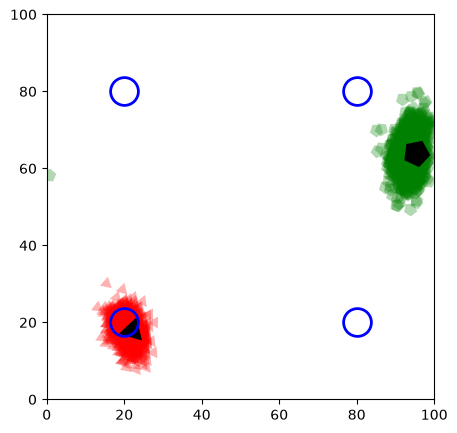

Average pacman distance before resample: 3.7396719440544666
Average ghost distance before resample: 4.841938683793386


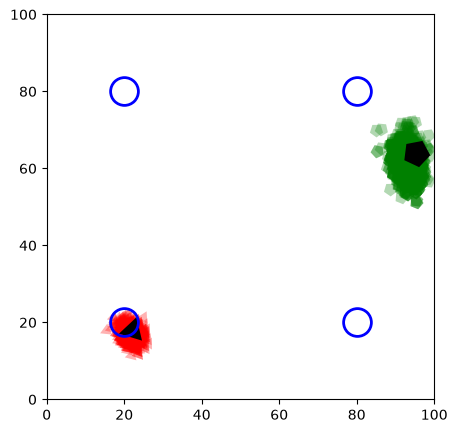

Average pacman distance after resample: 2.260317551016638
Average ghost distance after resample: 4.6700764134860435

Turn #10


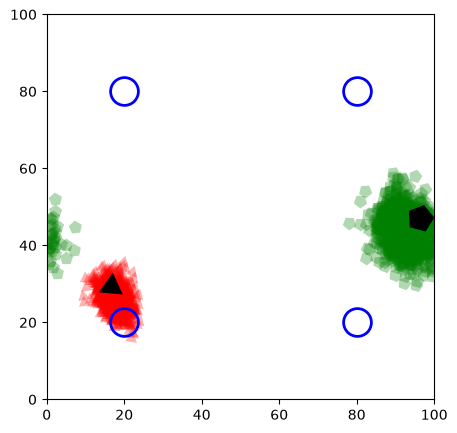

Average pacman distance before resample: 4.426004611320988
Average ghost distance before resample: 7.1469263734374575
Highest Pacman weight: 0.0032962703229718043
Highest Ghost weight: 0.0017421724993808233
Distinct Pacman particles: 479
Distinct Ghost particles: 563


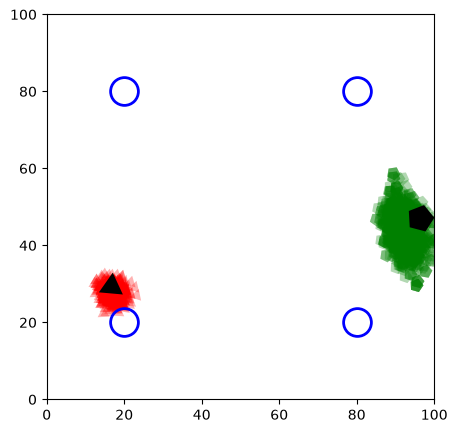

Average pacman distance after resample: 2.4379316308608905
Average ghost distance after resample: 6.779844656488017


In [5]:
for turn in range(T):
    print('\nTurn #{}'.format(turn+1))

    # real pacman movement
    # turn 0.1 and move 10 meters
    mypacman = mypacman.move(0.2, 10.0)

    # real move for ghost (random)
    gturn = (random.random()-0.5)*(math.pi/2.0) # random angle in [-45,45]
    gdist = random.random()*20.0           # random distance in [0,20]
    myghost = myghost.move(gturn, gdist)

    # elapse time
    # move particles using the same movement made by robot
    p2 = []
    g2 = []
    for i in range(N):
        p2.append(p[i].move(0.2, 10.0))
        g2.append(g[i].move(gturn, gdist))
    p = p2
    g = g2

    show_belief(mypacman, p, myghost, g)
    print("Average pacman distance before resample:", eval(mypacman, p))
    print("Average ghost distance before resample:", eval(myghost, g))

    # observe
    ZP = mypacman.sense()        # noisy measurement of the distance between the pacman and the landmarks
    ZG = myghost.sense(mypacman) # noisy measurement of the distance between the pacman and the ghost

    ###################################
    ###################################
    ###################################
    ###### YOUR CODE STARTS HERE ######
    ###################################
    ###################################
    ###################################

    # downweight and resample pacman and ghost particles here - check the Particle Filtering lecture for an example

    # particles do not know the real location of the pacman and the ghost, so you cannot access "mypacman" and "myghost" in here
    # remember that you can still use p and g, which can be used to estimate the location of the pacman and the ghost

    # you should use the obtained measurements from the sensors to update the particles
    # - ZP contains the observed distances between the pacman and the landmarks
    # - ZG is the observed distance between the pacman and the ghost


    # Calculating Pacman's particle weights and then normalising the weights

    weights = []

    for particle in p:
        weight = particle.measurement_prob(ZP)
        weights.append(weight)

    total_weights = sum(weights)

    if total_weights == 0:
        normalized_weights = [1/len(weights) for i in weights]
    else:
        normalized_weights = [(i / total_weights) for i in weights]

    cumulative_weights = []

    running_total = 0

    for i in normalized_weights:
        running_total += i
        cumulative_weights.append(running_total)

    cumulative_weights[-1] = 1.0

    resampled_particles = []

    for j in range(N):
        r = random.random()

        for i in range(len(cumulative_weights)):
            if r <= cumulative_weights[i]:
                selected_particle = p[i]
                break

        resampled_particles.append(selected_particle)

    p = resampled_particles


    # Calculating ghost's particle weights and then normalising the weights

    ghost_weights = []

    for particle in g:
        pacman_estimate = random.choice(p)
        ghost_weight = particle.measurement_prob(ZG, pacman_estimate)
        ghost_weights.append(ghost_weight)

    total_ghost_weights = sum(ghost_weights)

    if total_ghost_weights == 0:
        normalized_ghost_weights = [1/len(ghost_weights) for i in ghost_weights]
    else:
        normalized_ghost_weights = [(i / total_ghost_weights) for i in ghost_weights]

    cumulative_ghost_weights = []

    running_ghost_total = 0

    for i in normalized_ghost_weights:
        running_ghost_total += i
        cumulative_ghost_weights.append(running_ghost_total)

    cumulative_ghost_weights[-1] = 1.0

    resampled_ghost_particles = []

    for j in range(N):
        s = random.random()

        for i in range(len(cumulative_ghost_weights)):
            if s <= cumulative_ghost_weights[i]:
                selected_ghost_particle = g[i]
                break

        resampled_ghost_particles.append(selected_ghost_particle)

    g = resampled_ghost_particles

    if turn == T - 1:
        print("Highest Pacman weight:", max(normalized_weights))
        print("Highest Ghost weight:", max(normalized_ghost_weights))
        print("Distinct Pacman particles:", len({id(x) for x in p}))
        print("Distinct Ghost particles:", len({id(x) for x in g}))

    #################################
    #################################
    #################################
    ###### YOUR CODE ENDS HERE ######
    #################################
    #################################
    #################################

    show_belief(mypacman, p, myghost, g)
    print("Average pacman distance after resample:", eval(mypacman, p))
    print("Average ghost distance after resample:", eval(myghost, g))

# Implementation and results

## Solution description

For this project, I implemented a particle filtering algorithm to estimate the positions of Pacman and the ghost using 1,000 particles for each robot. For Pacman, I used the distance measurements from four landmarks to calculate the weights of its particles using the `measurement_prob()` function. I then normalized the weights and resampled the particles, giving higher-weight particles a greater chance of being selected. For the ghost, the process was more challenging because its only measurement was its distance from Pacman, and we could not access Pacman's actual position. To solve this, I randomly selected estimated Pacman positions from the updated particle distribution and used them to calculate the weights of the ghost particles based on the observed distance. I then normalized and resampled the ghost particles using the same method. This process was repeated over 10 turns, allowing both particle filters to update their estimates as the robots moved and received new sensor measurements.

I also considered using one representative Pacman position for all ghost particles or averaging each ghost particle’s measurement likelihood over several Pacman particles. Using one representative position would leave out some of the uncertainty in Pacman’s location, while averaging over multiple particles would require more calculations. I kept the random-selection approach because it was straightforward to implement and allowed different possible Pacman positions to influence the ghost’s weights. However, using only one Pacman particle per ghost particle introduces additional randomness. These alternatives were considered but were not implemented or tested.


## Experimental results

For the experimental results, I ran the particle filtering algorithm 10 separate times, with each experiment consisting of 10 turns. These statistics summarize the final Turn #10 errors after resampling across the 10 runs, using errors rounded to two decimal places and population standard deviation. Overall, Pacman performed more consistently than the ghost. Pacman had an average localization error of 2.76 and a standard deviation of 0.65, while the ghost had an average error of 13.00 and a much higher standard deviation of 11.69. Pacman's errors stayed between 2.10 and 4.21 across all experiments, showing that its particle filter was relatively accurate and consistent. The ghost's results varied much more, with errors ranging from 5.64 to 37.61. In most experiments, the ghost particles became concentrated near its actual position, but in Experiments 3 and 5, the localization errors were significantly higher. I also noticed that these unsuccessful runs had fewer distinct ghost particles remaining after resampling, suggesting that a loss of particle diversity may have contributed to the poor results. These experiments showed that although both particle filters can estimate the robots' positions, Pacman's filter was more reliable because it had more information available from the landmarks.

At initialization, both sets of particles were scattered throughout the environment. In the saved run, Pacman’s red particles became concentrated after the first measurement update and remained fairly tightly grouped, while the ghost’s green particles showed a broader distribution and separate possible regions during some intermediate turns. Movement spread the particles out, and the measurement updates often narrowed the distributions again, so uncertainty did not decrease steadily with every turn. This changing spread represents uncertainty about the robots’ positions, whereas the standard deviations calculated across the 10 experiments describe variation in their final localization errors.

The ghost particles can form a well-defined cluster when repeated distance measurements favor a particular group of possible positions. A single distance measurement leaves many possible ghost locations around Pacman, but later measurements and the movement model can help distinguish between those possibilities. Resampling repeatedly selects particles whose predicted distances agree with the observations, making the supported regions more concentrated. A more precise Pacman estimate also helps when evaluating the ghost particles. However, a tight cluster does not guarantee an accurate estimate, because resampling can also concentrate particles in an incorrect region.